In [27]:
import random
random.seed(42)

In [28]:
subjects = {"i": ("men", "1s"), "you": ("sen", "2s"), "he": ("u", "3s"),
    "she": ("u", "3s"), "we": ("biz", "1p"), "they": ("ular", "3p"),}
verbs = {"read":  {"en3": "reads",  "uz": {"1s":"o'qiyman","2s":"o'qiysan","3s":"o'qiydi","1p":"o'qiymiz","3p":"o'qishadi"},
              "neg": {"1s":"o'qimayman","2s":"o'qimaysan","3s":"o'qimaydi","1p":"o'qimaymiz","3p":"o'qishmaydi"},
              "obj": {"a book":"kitob","a newspaper":"gazeta","a letter":"xat"}},
    "write": {"en3": "writes", "uz": {"1s":"yozaman","2s":"yozasan","3s":"yozadi","1p":"yozamiz","3p":"yozishadi"},
              "neg": {"1s":"yozmayman","2s":"yozmaysan","3s":"yozmaydi","1p":"yozmaymiz","3p":"yozishmaydi"},
              "obj": {"a letter":"xat","a book":"kitob"}},
    "drink": {"en3": "drinks", "uz": {"1s":"ichaman","2s":"ichasan","3s":"ichadi","1p":"ichamiz","3p":"ichishadi"},
              "neg": {"1s":"ichmayman","2s":"ichmaysan","3s":"ichmaydi","1p":"ichmaymiz","3p":"ichishmaydi"},
              "obj": {"tea":"choy","water":"suv","milk":"sut","coffee":"qahva"}},
    "eat":   {"en3": "eats",   "uz": {"1s":"yeyman","2s":"yeysan","3s":"yeydi","1p":"yeymiz","3p":"yeyishadi"},
              "neg": {"1s":"yemayman","2s":"yemaysan","3s":"yemaydi","1p":"yemaymiz","3p":"yeyishmaydi"},
              "obj": {"bread":"non","an apple":"olma","meat":"go'sht","rice":"guruch"}},
}
places = {"": "", "at home": "uyda", "at school": "maktabda", "at work": "ishda", "in the park": "bog'da"}
times  = {"": "", "every day": "har kuni", "in the morning": "ertalab", "in the evening": "kechqurun", "on sunday": "yakshanba kuni"}

In [29]:
pairs=[]

In [30]:
for en_s, (uz_s, p) in subjects.items():
    for v, info in verbs.items():
        for en_o, uz_o in info["obj"].items():
            for en_pl, uz_pl in places.items():
                for en_t, uz_t in times.items():
                    for neg in [False, True]:
                        if neg:
                            aux = "does not" if p == "3s" else "do not"
                            en_v, uz_v = f"{aux} {v}", info["neg"][p]
                        else:
                            en_v, uz_v = (info["en3"] if p == "3s" else v), info["uz"][p]
                        en = " ".join(x for x in [en_s, en_v, en_o, en_pl, en_t] if x)
                        uz = " ".join(x for x in [uz_s, uz_t, uz_pl, uz_o, uz_v] if x)  # o'zbekcha tartib boshqacha!
                        if 5 <= len(en.split()) <= 8:
                            pairs.append((en, uz))

In [31]:
random.shuffle(pairs)
pairs=pairs[:2000]
print("Jami juftliklar: ", len(pairs))
for en, uz in pairs[:5]:
  print(f"{en:45s} -> {uz}")


Jami juftliklar:  2000
i write a book at school                      -> men maktabda kitob yozaman
he reads a letter in the evening              -> u kechqurun xat o'qiydi
you do not read a book at school              -> sen maktabda kitob o'qimaysan
he does not write a letter                    -> u xat yozmaydi
she does not read a book at school            -> u maktabda kitob o'qimaydi


In [32]:
PAD, SOS, EOS, UNK = "<pad>", "<sos>", "<eos>", "<unk>"
words = sorted({w for en, uz in pairs for w in (en + " " + uz).split()})
itos = [PAD, SOS, EOS, UNK] + words
stoi = {w: i for i, w in enumerate(itos)}
pad_id, sos_id, eos_id, unk_id = stoi[PAD], stoi[SOS], stoi[EOS], stoi[UNK]
vocab = len(itos)
print("Lug'at hajmi:", vocab)

Lug'at hajmi: 112


In [33]:
T = 10
def encode(sentence):
    return [stoi.get(w, unk_id) for w in sentence.split()]

def pad(ids, T=T):
    assert len(ids) <= T, "Gap T dan uzun!"
    return ids + [pad_id] * (T - len(ids))

en, uz = pairs[0]
print("\nMisol:", en)
print("  raqamlar:      ", encode(en))
print("  padding bilan: ", pad(encode(en)))
print("  orqaga:        ", [itos[i] for i in pad(encode(en))])


Misol: i write a book at school
  raqamlar:       [30, 87, 4, 10, 7, 72]
  padding bilan:  [30, 87, 4, 10, 7, 72, 0, 0, 0, 0]
  orqaga:         ['i', 'write', 'a', 'book', 'at', 'school', '<pad>', '<pad>', '<pad>', '<pad>']


In [34]:
def decode(ids):
    # Convert list of token IDs back to words, ignoring special padding and boundary tokens
    words = [itos[i] for i in ids if i not in (pad_id, sos_id, eos_id)]
    return " ".join(words)

# Quick test
sample_ids = pad(encode("i write a book at school"))
print("Original IDs:", sample_ids)
print("Decoded:", decode(sample_ids))

Original IDs: [30, 87, 4, 10, 7, 72, 0, 0, 0, 0]
Decoded: i write a book at school


In [35]:
encode("i love you")

[30, 3, 101]

In [36]:
import torch

src_list, tgt_in_list, tgt_out_list = [], [], []
for en, uz in pairs:
    uz_ids = encode(uz)
    src_list.append(pad(encode(en)))
    tgt_in_list.append(pad([sos_id] + uz_ids))
    tgt_out_list.append(pad(uz_ids + [eos_id]))

src     = torch.tensor(src_list)
tgt_in  = torch.tensor(tgt_in_list)
tgt_out = torch.tensor(tgt_out_list)
print("Shakllar:", src.shape, tgt_in.shape, tgt_out.shape)
i = 0
print("\nGap (en):", pairs[i][0])
print("Gap (uz):", pairs[i][1])
print("tgt_in :", [itos[t] for t in tgt_in[i].tolist()])
print("tgt_out:", [itos[t] for t in tgt_out[i].tolist()])

print("\nHar pozitsiyada model nimani o'rganadi:")
for a, b in zip(tgt_in[i].tolist(), tgt_out[i].tolist()):
    if b == pad_id:
        break
    print(f"  {itos[a]:>12s}  ->  {itos[b]}")

Shakllar: torch.Size([2000, 10]) torch.Size([2000, 10]) torch.Size([2000, 10])

Gap (en): i write a book at school
Gap (uz): men maktabda kitob yozaman
tgt_in : ['<sos>', 'men', 'maktabda', 'kitob', 'yozaman', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>']
tgt_out: ['men', 'maktabda', 'kitob', 'yozaman', '<eos>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>']

Har pozitsiyada model nimani o'rganadi:
         <sos>  ->  men
           men  ->  maktabda
      maktabda  ->  kitob
         kitob  ->  yozaman
       yozaman  ->  <eos>


In [37]:
import torch

src_list, tgt_in_list, tgt_out_list = [], [], []
for en, uz in pairs:
    uz_ids = encode(uz)
    src_list.append(pad(encode(en)))
    tgt_in_list.append(pad([sos_id] + uz_ids))
    tgt_out_list.append(pad(uz_ids + [eos_id]))

src     = torch.tensor(src_list)
tgt_in  = torch.tensor(tgt_in_list)
tgt_out = torch.tensor(tgt_out_list)
print("Shakllar:", src.shape, tgt_in.shape, tgt_out.shape)
i = 0
print("\nGap (en):", pairs[i][0])
print("Gap (uz):", pairs[i][1])
print("tgt_in :", [itos[t] for t in tgt_in[i].tolist()])
print("tgt_out:", [itos[t] for t in tgt_out[i].tolist()])

print("\nHar pozitsiyada model nimani o'rganadi:")
for a, b in zip(tgt_in[i].tolist(), tgt_out[i].tolist()):
    if b == pad_id:
        break
    print(f"  {itos[a]:>12s}  ->  {itos[b]}")

Shakllar: torch.Size([2000, 10]) torch.Size([2000, 10]) torch.Size([2000, 10])

Gap (en): i write a book at school
Gap (uz): men maktabda kitob yozaman
tgt_in : ['<sos>', 'men', 'maktabda', 'kitob', 'yozaman', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>']
tgt_out: ['men', 'maktabda', 'kitob', 'yozaman', '<eos>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>']

Har pozitsiyada model nimani o'rganadi:
         <sos>  ->  men
           men  ->  maktabda
      maktabda  ->  kitob
         kitob  ->  yozaman
       yozaman  ->  <eos>


In [38]:
import torch
import torch.nn as nn

class Seq2Seq(nn.Module):
    def __init__(self, vocab, T, C):
        super().__init__()
        self.src_tok = nn.Embedding(vocab, C)
        self.tgt_tok = nn.Embedding(vocab, C)
        self.pos = nn.Embedding(T, C)
        self.tf = nn.Transformer(d_model=C, nhead=2, num_encoder_layers=2,
                                 num_decoder_layers=2, dim_feedforward=4 * C,
                                 batch_first=True)
        self.out = nn.Linear(C, vocab)

    def embed(self, tok, ids):
        return tok(ids) + self.pos(torch.arange(ids.size(1)))

    def forward(self, src, tgt_in):
        mask = nn.Transformer.generate_square_subsequent_mask(tgt_in.size(1))
        s = self.embed(self.src_tok, src)
        t = self.embed(self.tgt_tok, tgt_in)
        h = self.tf(s, t, tgt_mask=mask)
        return self.out(h)

torch.manual_seed(0)
model = Seq2Seq(vocab, T, C=64)
logits = model(src[:4], tgt_in[:4])
print("logits shakli:", logits.shape)
print("Mask:\n", nn.Transformer.generate_square_subsequent_mask(5))

logits shakli: torch.Size([4, 10, 112])
Mask:
 tensor([[0., -inf, -inf, -inf, -inf],
        [0., 0., -inf, -inf, -inf],
        [0., 0., 0., -inf, -inf],
        [0., 0., 0., 0., -inf],
        [0., 0., 0., 0., 0.]])


Train: 1800 | Test: 200
Epoch  1/30  loss = 3.3540
Epoch  2/30  loss = 1.8993
Epoch  3/30  loss = 0.9668
Epoch  4/30  loss = 0.4789
Epoch  5/30  loss = 0.2783
Epoch  6/30  loss = 0.1832
Epoch  7/30  loss = 0.1279
Epoch  8/30  loss = 0.0894
Epoch  9/30  loss = 0.0663
Epoch 10/30  loss = 0.0520
Epoch 11/30  loss = 0.0414
Epoch 12/30  loss = 0.0339
Epoch 13/30  loss = 0.0352
Epoch 14/30  loss = 0.0262
Epoch 15/30  loss = 0.0221
Epoch 16/30  loss = 0.0192
Epoch 17/30  loss = 0.0181
Epoch 18/30  loss = 0.0135
Epoch 19/30  loss = 0.0146
Epoch 20/30  loss = 0.0124
Epoch 21/30  loss = 0.0100
Epoch 22/30  loss = 0.0096
Epoch 23/30  loss = 0.0095
Epoch 24/30  loss = 0.0129
Epoch 25/30  loss = 0.0103
Epoch 26/30  loss = 0.0073
Epoch 27/30  loss = 0.0060
Epoch 28/30  loss = 0.0062
Epoch 29/30  loss = 0.0081
Epoch 30/30  loss = 0.0063


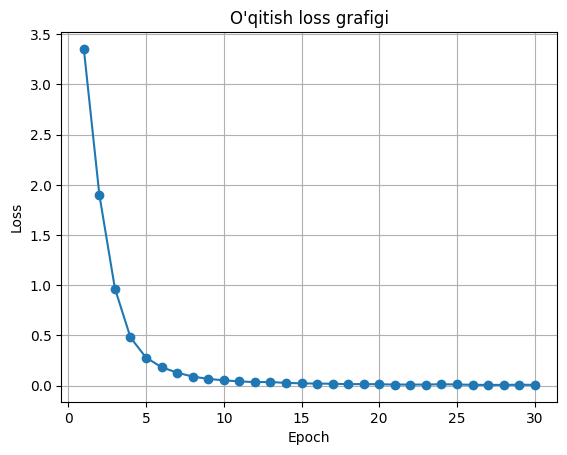

In [39]:
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt


n_train = int(0.9 * len(src))
train_ds = TensorDataset(src[:n_train], tgt_in[:n_train], tgt_out[:n_train])
test_pairs = pairs[n_train:]
train_dl = DataLoader(train_ds, batch_size=64, shuffle=True)
print("Train:", n_train, "| Test:", len(test_pairs))

torch.manual_seed(0)
model = Seq2Seq(vocab, T, C=64)
loss_fn = nn.CrossEntropyLoss(ignore_index=pad_id)
opt = torch.optim.AdamW(model.parameters(), lr=1e-3)
EPOCHS = 30
losses = []
for epoch in range(EPOCHS):
    model.train()
    total = 0
    for s, ti, to in train_dl:
        logits = model(s, ti)
        loss = loss_fn(logits.reshape(-1, vocab), to.reshape(-1))
        opt.zero_grad()
        loss.backward()
        opt.step()
        total += loss.item()
    avg = total / len(train_dl)
    losses.append(avg)
    print(f"Epoch {epoch+1:2d}/{EPOCHS}  loss = {avg:.4f}")
plt.plot(range(1, EPOCHS + 1), losses, marker="o")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title("O'qitish loss grafigi")
plt.grid(True)
plt.savefig("loss.png")
plt.show()

In [40]:
def translate(model, src_ids, sos_id, eos_id, max_len):
    model.eval()
    tgt = torch.tensor([[sos_id]])
    with torch.no_grad():
        for _ in range(max_len):
            logits = model(src_ids, tgt)
            next_id = logits[0, -1].argmax().item()
            tgt = torch.cat([tgt, torch.tensor([[next_id]])], dim=1)
            if next_id == eos_id:
                break
    return tgt

def tarjima(sentence):
    src_ids = torch.tensor([pad(encode(sentence))])
    out = translate(model, src_ids, sos_id, eos_id, max_len=T - 1)
    words = [itos[t] for t in out[0].tolist()]
    return " ".join(w for w in words if w not in (PAD, SOS, EOS))

print(tarjima("i drink tea at home"))

men uyda choy ichaman


In [41]:
correct = sum(tarjima(en) == uz for en, uz in test_pairs)
print(f"Test aniqligi: {correct}/{len(test_pairs)}\n")
examples = [
    "she does not eat meat at work",
    "they read a newspaper at work on sunday",
    "i drink coffee at work in the morning",
    "we write a letter",
    "they do not write a newspaper",
    "i drink a book at home",
    "i drink tea at home in the morning every day",
    "school at i read a book",
    "i i i i i",
    "he eats tea every day",
]
for en in examples:
    print(f"{en:45s} -> {tarjima(en)}")

Test aniqligi: 200/200

she does not eat meat at work                 -> u ishda go'sht yemaydi
they read a newspaper at work on sunday       -> ular yakshanba kuni ishda gazeta o'qishadi
i drink coffee at work in the morning         -> men ertalab ishda qahva ichaman
we write a letter                             -> biz xat yozamiz
they do not write a newspaper                 -> ular gazeta yozishmaydi
i drink a book at home                        -> men uyda kitob ichaman
i drink tea at home in the morning every day  -> men ertalab uyda choy ichaman
school at i read a book                       -> u kitob o'qimayman
i i i i i                                     -> men men go'sht yeyman
he eats tea every day                         -> u har kuni choy yeydi


C=  4 | parametrlar=   2664 | loss=2.6187 | test aniqligi=0% | 15s
C=  8 | parametrlar=   7008 | loss=1.3946 | test aniqligi=2% | 17s
C= 16 | parametrlar=  21072 | loss=0.2658 | test aniqligi=92% | 18s
C= 64 | parametrlar= 255984 | loss=0.0063 | test aniqligi=100% | 39s


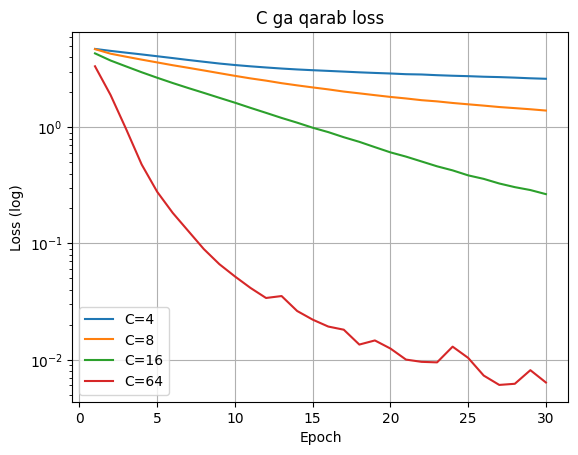

In [42]:
import time

def train_model(model, epochs=30):
    opt = torch.optim.AdamW(model.parameters(), lr=1e-3)
    hist = []
    for epoch in range(epochs):
        model.train(); total = 0
        for s, ti, to in train_dl:
            loss = loss_fn(model(s, ti).reshape(-1, vocab), to.reshape(-1))
            opt.zero_grad(); loss.backward(); opt.step()
            total += loss.item()
        hist.append(total / len(train_dl))
    return hist

def accuracy(m):
    ok = 0
    for en, uz in test_pairs:
        out = translate(m, torch.tensor([pad(encode(en))]), sos_id, eos_id, max_len=T - 1)
        pred = " ".join(itos[t] for t in out[0].tolist() if t not in (pad_id, sos_id, eos_id))
        ok += pred == uz
    return ok / len(test_pairs)

results = {}
for C in [4, 8, 16, 64]:
    torch.manual_seed(0)
    m = Seq2Seq(vocab, T, C=C)
    n_params = sum(p.numel() for p in m.parameters())
    t0 = time.time()
    hist = train_model(m, epochs=30)
    results[C] = hist
    print(f"C={C:3d} | parametrlar={n_params:7d} | loss={hist[-1]:.4f} | "
          f"test aniqligi={accuracy(m):.0%} | {time.time()-t0:.0f}s")

for C, hist in results.items():
    plt.plot(range(1, 31), hist, label=f"C={C}")
plt.xlabel("Epoch"); plt.ylabel("Loss (log)"); plt.yscale("log")
plt.legend(); plt.grid(True); plt.title("C ga qarab loss")
plt.savefig("experiment.png"); plt.show()

C=  4 | parametrlar=   2664 | loss=2.6187 | test aniqligi=0% | 16s
C=  8 | parametrlar=   7008 | loss=1.3946 | test aniqligi=2% | 16s
C= 16 | parametrlar=  21072 | loss=0.2658 | test aniqligi=92% | 18s
C= 64 | parametrlar= 255984 | loss=0.0063 | test aniqligi=100% | 39s


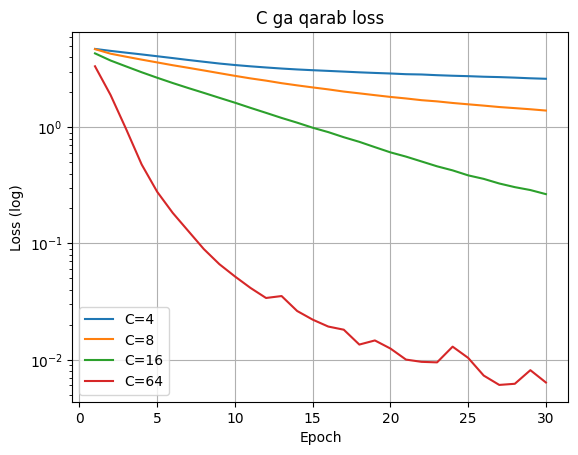

In [43]:
import time

def train_model(model, epochs=30):
    opt = torch.optim.AdamW(model.parameters(), lr=1e-3)
    hist = []
    for epoch in range(epochs):
        model.train(); total = 0
        for s, ti, to in train_dl:
            loss = loss_fn(model(s, ti).reshape(-1, vocab), to.reshape(-1))
            opt.zero_grad(); loss.backward(); opt.step()
            total += loss.item()
        hist.append(total / len(train_dl))
    return hist

def accuracy(m):
    ok = 0
    for en, uz in test_pairs:
        out = translate(m, torch.tensor([pad(encode(en))]), sos_id, eos_id, max_len=T - 1)
        pred = " ".join(itos[t] for t in out[0].tolist() if t not in (pad_id, sos_id, eos_id))
        ok += pred == uz
    return ok / len(test_pairs)

results = {}
for C in [4, 8, 16, 64]:
    torch.manual_seed(0)
    m = Seq2Seq(vocab, T, C=C)
    n_params = sum(p.numel() for p in m.parameters())
    t0 = time.time()
    hist = train_model(m, epochs=30)
    results[C] = hist
    print(f"C={C:3d} | parametrlar={n_params:7d} | loss={hist[-1]:.4f} | "
          f"test aniqligi={accuracy(m):.0%} | {time.time()-t0:.0f}s")

for C, hist in results.items():
    plt.plot(range(1, 31), hist, label=f"C={C}")
plt.xlabel("Epoch"); plt.ylabel("Loss (log)"); plt.yscale("log")
plt.legend(); plt.grid(True); plt.title("C ga qarab loss")
plt.savefig("experiment.png"); plt.show()

In [44]:
class Seq2SeqNoMask(Seq2Seq):
    def forward(self, src, tgt_in):
        s = self.embed(self.src_tok, src)
        t = self.embed(self.tgt_tok, tgt_in)
        h = self.tf(s, t)
        return self.out(h)

torch.manual_seed(0)
nm = Seq2SeqNoMask(vocab, T, C=64)
hist_nm = train_model(nm, epochs=30)

print("Epoch:          1      5      10     30")
print("Mask bilan:  ", [round(results[64][i], 3) for i in [0, 4, 9, 29]])
print("Mask'siz:    ", [round(hist_nm[i], 3) for i in [0, 4, 9, 29]])
print(f"\nMask'siz test aniqligi: {accuracy(nm):.0%}")

for en in ["i drink tea at home", "we write a letter"]:
    out = translate(nm, torch.tensor([pad(encode(en))]), sos_id, eos_id, max_len=T - 1)
    print(en, "->", " ".join(itos[t] for t in out[0].tolist()[1:]))

Epoch:          1      5      10     30
Mask bilan:   [3.354, 0.278, 0.052, 0.006]
Mask'siz:     [3.313, 0.214, 0.033, 0.004]

Mask'siz test aniqligi: 54%
i drink tea at home -> men uyda uyda uyda choy ichaman <eos>
we write a letter -> biz xat xat yozamiz ichamiz <eos>


In [45]:
UNK = "<unk>"
noun_map = {"book":"kitob","newspaper":"gazeta","letter":"xat","tea":"choy","water":"suv",
            "milk":"sut","coffee":"qahva","bread":"non","apple":"olma","meat":"go'sht","rice":"guruch"}

random.seed(1)
aug_pairs = []
for en, uz in pairs:
    if random.random() < 0.2:
        en_w, uz_w = en.split(), uz.split()
        for e, u in noun_map.items():
            if e in en_w and u in uz_w:
                en_w[en_w.index(e)] = UNK
                uz_w[uz_w.index(u)] = UNK
                break
        aug_pairs.append((" ".join(en_w), " ".join(uz_w)))
    else:
        aug_pairs.append((en, uz))

print("Misollar:")
for en, uz in [p for p in aug_pairs if UNK in p[0]][:3]:
    print(f"  {en:40s} -> {uz}")
itos_u = [PAD, SOS, EOS, UNK] + words
stoi_u = {w: i for i, w in enumerate(itos_u)}
unk_id = stoi_u[UNK]
vocab_u = len(itos_u)

def encode_u(sentence):
    return [stoi_u.get(w, unk_id) for w in sentence.split()]

print("\nencode_u('i love you') =", encode_u("i love you"), " <- endi xato yo'q!")
S, TI, TO = [], [], []
for en, uz in aug_pairs:
    ids = encode_u(uz)
    S.append(pad(encode_u(en))); TI.append(pad([sos_id] + ids)); TO.append(pad(ids + [eos_id]))
S, TI, TO = torch.tensor(S), torch.tensor(TI), torch.tensor(TO)
dl_u = DataLoader(TensorDataset(S[:n_train], TI[:n_train], TO[:n_train]), batch_size=64, shuffle=True)

torch.manual_seed(0)
model_u = Seq2Seq(vocab_u, T, C=64)
opt = torch.optim.AdamW(model_u.parameters(), lr=1e-3)
for epoch in range(30):
    model_u.train(); total = 0
    for s, ti, to in dl_u:
        loss = loss_fn(model_u(s, ti).reshape(-1, vocab_u), to.reshape(-1))
        opt.zero_grad(); loss.backward(); opt.step(); total += loss.item()
print("Yakuniy loss:", round(total / len(dl_u), 4))
def tarjima_u(sentence):
    src_ids = torch.tensor([pad(encode_u(sentence))])
    out = translate(model_u, src_ids, sos_id, eos_id, max_len=T - 1)
    words_out = [itos_u[t] for t in out[0].tolist() if t not in (pad_id, sos_id, eos_id)]
    unknown = [w for w in sentence.split() if w not in stoi_u]
    return " ".join(f"[{unknown.pop(0)}]" if w == UNK and unknown else w for w in words_out)

print()
for en in ["i drink juice at home", "she eats a banana every day",
           "they do not drink lemonade in the evening", "i read a magazine in the park",
           "we buy bread at school", "i love you"]:
    print(f"{en:45s} -> {tarjima_u(en)}")

Misollar:
  i write a <unk> at school                -> men maktabda <unk> yozaman
  he does not drink <unk> every day        -> u har kuni <unk> ichmaydi
  he writes a <unk> at school on sunday    -> u yakshanba kuni maktabda <unk> yozadi

encode_u('i love you') = [30, 3, 101]  <- endi xato yo'q!
Yakuniy loss: 0.0052

i drink juice at home                         -> men uyda [juice] ichaman
she eats a banana every day                   -> u har kuni [banana] yeydi
they do not drink lemonade in the evening     -> ular kechqurun [lemonade] ichishmaydi
i read a magazine in the park                 -> men bog'da [magazine] o'qiyman
we buy bread at school                        -> biz maktabda non yeymiz
i love you                                    -> men [love] yeyman


In [46]:
import re

def tozalash(text):
    """Foydalanuvchi matnini model tushunadigan ko'rinishga keltiradi."""
    text = text.lower().strip()
    text = text.replace("’", "'")
    text = text.replace("don't", "do not").replace("doesn't", "does not")
    text = re.sub(r"[^a-z' ]", " ", text)
    return " ".join(text.split())

def foydalanuvchi_tarjima(text):
    gap = tozalash(text)
    if not gap:
        return None, ["Bo'sh gap kiritildi."]
    ogohlantirish = []
    soz = gap.split()
    if len(soz) > T:
        ogohlantirish.append(f"Gap juda uzun ({len(soz)} so'z). Faqat birinchi {T} ta so'z olindi.")
        soz = soz[:T]
        gap = " ".join(soz)
    notanish = [w for w in soz if w not in stoi_u]
    if len(notanish) > len(soz) / 2:
        return None, [f"Gapdagi so'zlarning ko'pini model bilmaydi ({', '.join(notanish)}). "
                      "Bu gap model o'rgangan mavzudan tashqarida."]
    if notanish:
        ogohlantirish.append("Model bu so'zlarni bilmaydi: " + ", ".join(notanish))
    return tarjima_u(gap), ogohlantirish
en_words = sorted({w for en, uz in pairs for w in en.split()})
print("Model biladigan so'zlar:", ", ".join(en_words))
print("Misol: I drink tea at home every day")
print("Chiqish uchun: exit\n")

while True:
    text = input("🇬🇧 Inglizcha gap: ")
    if text.strip().lower() in ("exit", "chiqish", "q"):
        print("Xayr!")
        break
    natija, ogoh = foydalanuvchi_tarjima(text)
    for o in ogoh:
        print("   ⚠️", o)
    if natija:
        print("🇺🇿 O'zbekcha:", natija)
    print()

Model biladigan so'zlar: a, an, apple, at, book, bread, coffee, day, do, does, drink, drinks, eat, eats, evening, every, he, home, i, in, letter, meat, milk, morning, newspaper, not, on, park, read, reads, rice, school, she, sunday, tea, the, they, water, we, work, write, writes, you
Misol: I drink tea at home every day
Chiqish uchun: exit

🇬🇧 Inglizcha gap: go back
   ⚠️ Gapdagi so'zlarning ko'pini model bilmaydi (go, back). Bu gap model o'rgangan mavzudan tashqarida.

🇬🇧 Inglizcha gap: bread and coffee
   ⚠️ Model bu so'zlarni bilmaydi: and
🇺🇿 O'zbekcha: sen qahva ichmaysan

🇬🇧 Inglizcha gap: coffee
🇺🇿 O'zbekcha: men qahva yeyishadi

🇬🇧 Inglizcha gap: exit
Xayr!
